# DSCI 552 - Homework 6

**Name:** Ruturaj Mohalkar  
**GitHub Username:** ruturaj-mohalkar-25  
**USC ID:** 6930537443

## Setup

XGBoost in 1(e) and 1(f) needs an OpenMP runtime, which macOS does not ship. The cell below installs it with Homebrew. It is only needed on macOS.

In [1]:
!brew install libomp 2>/dev/null | tail -1

## Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.optimize import linprog
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.svm import SVC

RANDOM_STATE = 42

# 1. Tree-Based Methods

## 1(a) The APS Failure data

Downloaded from the UCI Machine Learning Repository and saved as `data/aps_failure_training_set.csv` and `data/aps_failure_test_set.csv`. The files start with a 20 line license notice (`skiprows=20`), missing values are written `na`, and `class` is mapped from `neg`/`pos` to 0/1.

In [3]:
train = pd.read_csv('../data/aps_failure_training_set.csv', skiprows=20, na_values='na')
test = pd.read_csv('../data/aps_failure_test_set.csv', skiprows=20, na_values='na')

y_train = (train['class'] == 'pos').astype(int).to_numpy()
y_test = (test['class'] == 'pos').astype(int).to_numpy()
X_train_raw = train.drop(columns='class')
X_test_raw = test.drop(columns='class')

print('training set:', train.shape, '| positives:', y_train.sum())
print('test set    :', test.shape, '| positives:', y_test.sum())
print('non-numeric feature columns:', int((X_train_raw.dtypes == object).sum()))

training set: (60000, 171) | positives: 1000
test set    : (16000, 171) | positives: 375
non-numeric feature columns: 0


## 1(b) Data preparation

### 1(b)i Missing values

**Techniques usually used for missing data:**

| Technique | Idea |
|---|---|
| Deletion | Drop rows or columns with missing values. Fine when few are missing. |
| Mean, median or mode imputation | Fill with a column statistic. The median is robust to outliers and skew. |
| Constant or indicator imputation | Fill with a fixed value, optionally adding a 0/1 missing flag. |
| Hot deck and k-nearest-neighbours | Copy values from the most similar complete rows. |
| Regression imputation | Predict the missing value from the other features. |
| Multiple or iterative imputation (MICE) | Regress each feature on the others in turn, optionally drawing several completed data sets. |
| Native handling | Some tree learners (XGBoost) learn a default direction for missing values. |

**Method used: median imputation.** The counts are strongly right skewed with large outliers, so the median is safer than the mean. As in the footnote of the question, the training set is filled with training statistics and the test set with test statistics.

In [4]:
print(f'cells missing in training set : {X_train_raw.isna().to_numpy().mean():.2%}')
print(f'rows with at least one missing  : {X_train_raw.isna().any(axis=1).sum()} of {len(X_train_raw)}')
complete = ~X_train_raw.isna().any(axis=1)
print(f'complete rows: {complete.sum()}, of which positive: {int(y_train[complete].sum())} (of {y_train.sum()} positives)')
print('columns with the most missing values:')
print(X_train_raw.isna().mean().sort_values(ascending=False).head(5).round(3))

X_train = X_train_raw.fillna(X_train_raw.median())
X_test = X_test_raw.fillna(X_test_raw.median())
print('\nmissing values left:', int(X_train.isna().sum().sum()), '(train),', int(X_test.isna().sum().sum()), '(test)')

cells missing in training set : 8.33%
rows with at least one missing  : 59409 of 60000
complete rows: 591, of which positive: 76 (of 1000 positives)
columns with the most missing values:
br_000    0.821
bq_000    0.812
bp_000    0.796
bo_000    0.772
cr_000    0.772
dtype: float64

missing values left: 0 (train), 0 (test)


**Result.** Deleting rows is not an option: only 591 of the 60,000 training rows are complete, and they hold 76 of the 1,000 positives. Median imputation keeps every row. Its cost is that a column with about 80% missing values becomes mostly constant, which lowers its CV.

### 1(b)ii Coefficient of variation

For each of the 170 features, CV = s / m, where s is the sample standard deviation and m is the sample mean, computed on the imputed training data.

In [5]:
cv = (X_train.std(ddof=1) / X_train.mean()).sort_values(ascending=False)
print('10 largest CV values:')
print(cv.head(10).round(2))
print('\nfeatures with CV = 0 (constant):', list(cv[cv == 0].index))

10 largest CV values:
cf_000    244.89
co_000    244.51
ad_000    244.32
cs_009    237.93
dh_000    123.22
dj_000    117.49
ag_000     92.92
as_000     87.33
ay_009     84.73
ak_000     80.42
dtype: float64

features with CV = 0 (constant): ['cd_000']


### 1(b)iii Correlation matrix

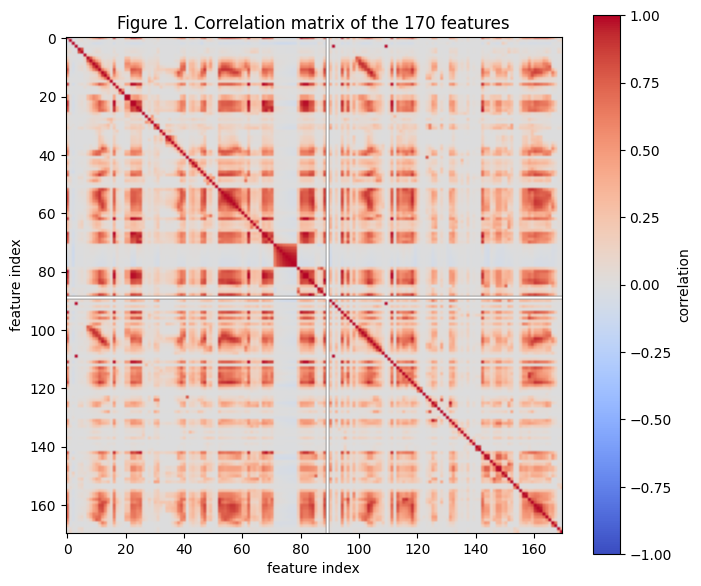

smallest correlation: -0.106
feature pairs with |correlation| > 0.9: 130 of 14196


In [6]:
corr = X_train.corr()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label='correlation')
ax.set_title('Figure 1. Correlation matrix of the 170 features')
ax.set_xlabel('feature index'); ax.set_ylabel('feature index')
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
print(f'smallest correlation: {upper.min().min():.3f}')
print('feature pairs with |correlation| > 0.9:', int((upper.abs() > 0.9).sum().sum()), 'of', int(upper.notna().sum().sum()))

**Result.** The features are related in blocks: 130 of the 14,196 pairs have a correlation above 0.9, and the smallest correlation is -0.106. The blank row and column at index 89 belong to `cd_000`, which is constant. Correlated features do not hurt trees but would make linear coefficients unstable.

### 1(b)iv Features with the highest CV

The number of features to plot is floor(sqrt(170)) = 13. Figure 2 shows scatter plots of consecutive pairs of them and Figure 3 shows box plots by class, in the style of ISLR p. 129. The axes use a symmetric log scale, because on a linear axis the extreme values collapse every point into one corner.

13 features: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


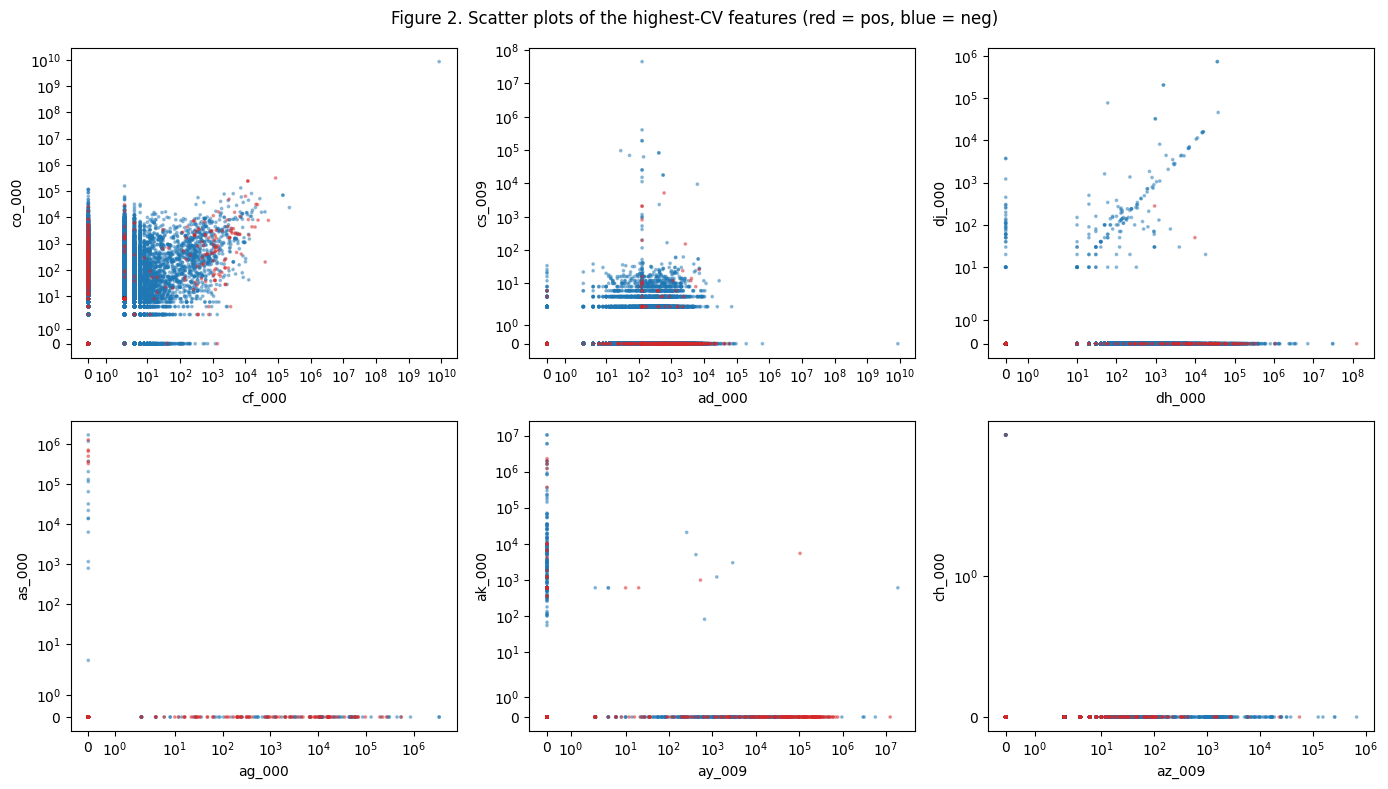

In [7]:
n_top = int(np.floor(np.sqrt(170)))
top = list(cv.head(n_top).index)
print(n_top, 'features:', top)

colors = np.where(y_train == 1, 'tab:red', 'tab:blue')
order = np.argsort(y_train)            # draw the positives last so they stay visible
pairs = [(top[i], top[i + 1]) for i in range(0, n_top - 1, 2)]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (a, b) in zip(axes.ravel(), pairs):
    ax.scatter(X_train[a].to_numpy()[order], X_train[b].to_numpy()[order], c=colors[order], s=3, alpha=0.4)
    ax.set_xscale('symlog'); ax.set_yscale('symlog')   # a few huge values hide everything else on a linear axis
    ax.set_xlabel(a); ax.set_ylabel(b)
fig.suptitle('Figure 2. Scatter plots of the highest-CV features (red = pos, blue = neg)')
plt.tight_layout(); plt.show()

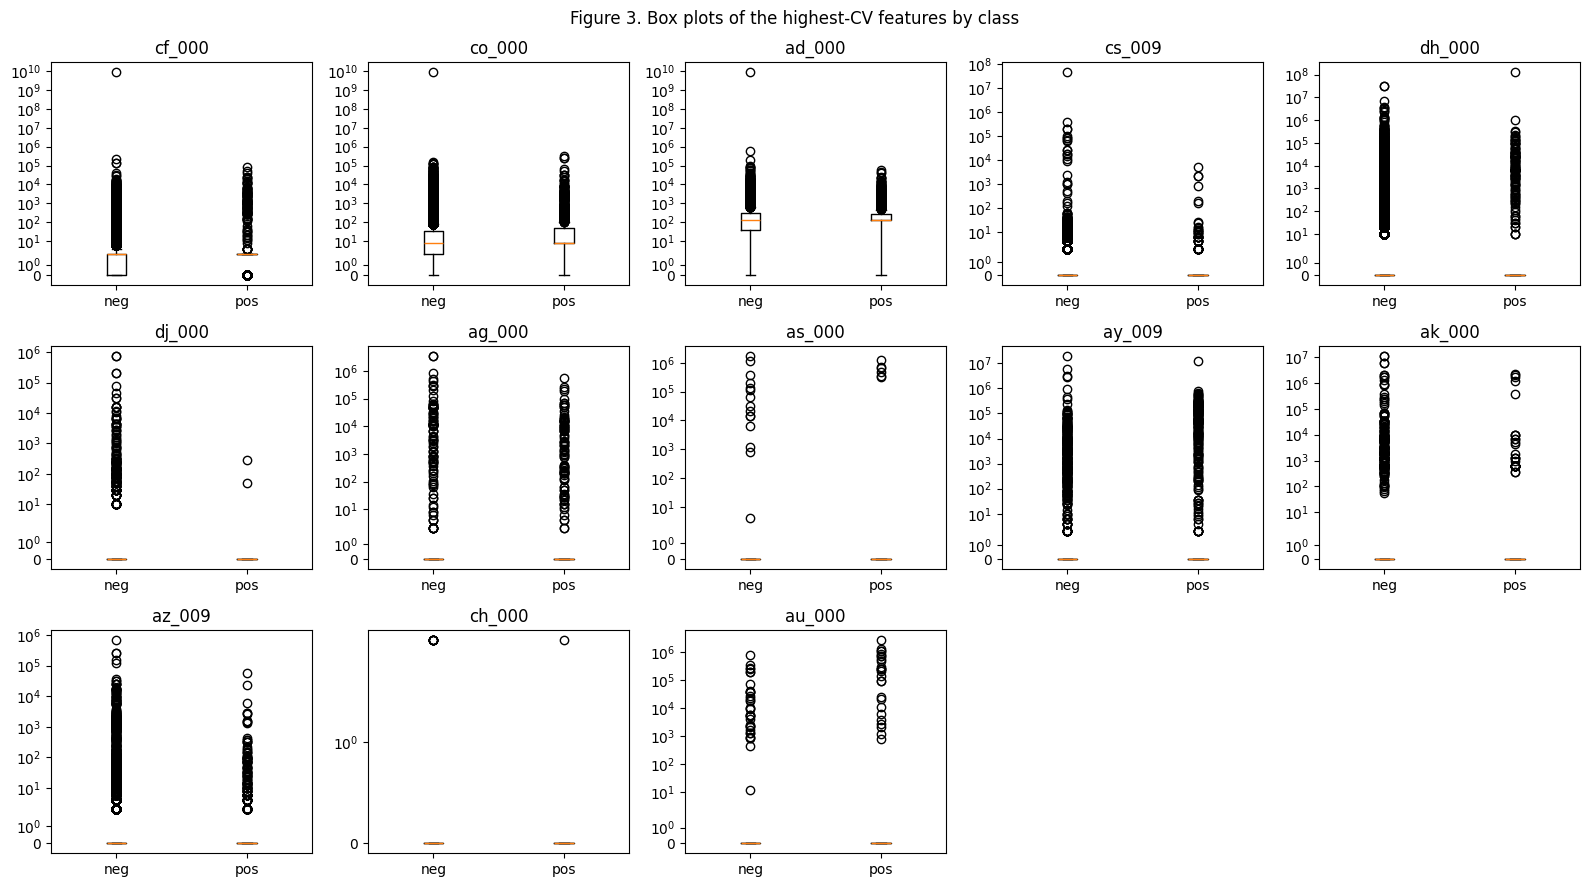

        median neg  median pos  share zero neg  share zero pos
cf_000         2.0         2.0            0.36            0.20
co_000         8.0         8.0            0.22            0.04
ad_000       126.0       126.0            0.03            0.03
cs_009         0.0         0.0            0.95            0.95
dh_000         0.0         0.0            0.88            0.88
dj_000         0.0         0.0            1.00            1.00
ag_000         0.0         0.0            1.00            0.90
as_000         0.0         0.0            1.00            0.99
ay_009         0.0         0.0            0.99            0.79
ak_000         0.0         0.0            0.99            0.97
az_009         0.0         0.0            0.97            0.82
ch_000         0.0         0.0            1.00            1.00
au_000         0.0         0.0            1.00            0.97


In [8]:
fig, axes = plt.subplots(3, 5, figsize=(16, 9))
for ax, f in zip(axes.ravel(), top):
    ax.boxplot([X_train.loc[y_train == 0, f], X_train.loc[y_train == 1, f]], tick_labels=['neg', 'pos'])
    ax.set_yscale('symlog')
    ax.set_title(f)
for ax in axes.ravel()[n_top:]:
    ax.axis('off')
fig.suptitle('Figure 3. Box plots of the highest-CV features by class')
plt.tight_layout(); plt.show()

neg_rows, pos_rows = X_train[y_train == 0], X_train[y_train == 1]
print(pd.DataFrame({'median neg': neg_rows[top].median(), 'median pos': pos_rows[top].median(),
                    'share zero neg': (neg_rows[top] == 0).mean(), 'share zero pos': (pos_rows[top] == 0).mean()}).round(2))

**Conclusions.** In Figure 2 the positives (red) lie over the same region as the negatives (blue), and no pair separates the classes. In Figure 3 and the table the median is the same in both classes for all 13 features and most values are 0, so the differences are in the tails. The share of zeros does differ for some features: for `co_000` it is 4% among positives and 22% among negatives, for `ay_009` 79% against 99%, and `cf_000`, `az_009` and `ag_000` also have fewer zeros among positives.

**Can we conclude significance from the plots alone? No.** With 59 negatives per positive, the negative points hide the positive ones. A few extreme values dominate the scales, and a plot gives no test statistic and ignores the other features. The plots only suggest candidates (`co_000`, `cf_000`, `ay_009`, `az_009`, `ag_000`). A high CV does not mean a feature is useful: here it mostly reflects a few huge values in a column of zeros.

### 1(b)v Class balance

In [9]:
for name, y in [('training', y_train), ('test', y_test)]:
    n_pos = int(y.sum()); n_neg = len(y) - n_pos
    print(f'{name:9s}: neg = {n_neg}, pos = {n_pos}, positive share = {n_pos / len(y):.2%}, neg:pos = {n_neg / n_pos:.0f}:1')

training : neg = 59000, pos = 1000, positive share = 1.67%, neg:pos = 59:1
test     : neg = 15625, pos = 375, positive share = 2.34%, neg:pos = 42:1


**Result.** The data is highly imbalanced: positives are 1.67% of the training set (59 negatives per positive) and 2.34% of the test set. Always answering neg would give errors of 1.67% and 2.34%, so the error alone says little. The confusion matrix (especially false negatives) and the AUC are needed.

## 1(c) Random forest without compensating for class imbalance

A random forest with 100 trees is trained on the imputed training set with no class weights. Confusion matrices use the predicted class. The out-of-bag (OOB) error comes from the training rows each tree did not see.

In [10]:
results = []

def evaluate(name, model, X_tr, X_te):
    """Print the confusion matrix, misclassification error and AUC for train and test, and plot the ROC curves."""
    fig, ax = plt.subplots(figsize=(5, 5))
    for split, X, y in [('train', X_tr, y_train), ('test', X_te, y_test)]:
        prob = model.predict_proba(X)[:, 1]
        pred = model.predict(X)
        tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
        err, auc = (pred != y).mean(), roc_auc_score(y, prob)
        results.append(dict(model=name, split=split, error=err, auc=auc, TN=tn, FP=fp, FN=fn, TP=tp))
        print(f'{name} | {split}: misclassification = {err:.4f}, AUC = {auc:.4f}')
        print(pd.DataFrame([[tn, fp], [fn, tp]], index=['actual neg', 'actual pos'], columns=['pred neg', 'pred pos']), '\n')
        fpr, tpr, _ = roc_curve(y, prob)
        ax.plot(fpr, tpr, label=f'{split} (AUC = {auc:.4f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_xlabel('false positive rate'); ax.set_ylabel('true positive rate'); ax.legend(loc='lower right')
    return ax

RF | train: misclassification = 0.0000, AUC = 1.0000
            pred neg  pred pos
actual neg     59000         0
actual pos         1       999 

RF | test: misclassification = 0.0076, AUC = 0.9928
            pred neg  pred pos
actual neg     15610        15
actual pos       106       269 



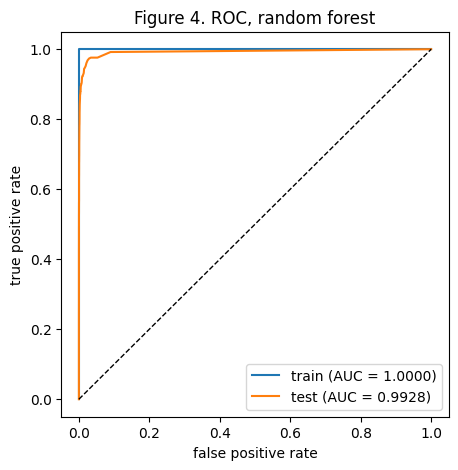

OOB error estimate = 0.0061  |  test error = 0.0076


In [11]:
rf = RandomForestClassifier(n_estimators=100, oob_score=True, n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
ax = evaluate('RF', rf, X_train, X_test)
ax.set_title('Figure 4. ROC, random forest'); plt.show()

oob_err = 1 - rf.oob_score_
print(f'OOB error estimate = {oob_err:.4f}  |  test error = {results[-1]["error"]:.4f}')

**Results.** On the training set the forest is nearly perfect (error 0.0000, AUC 1.0000, one false negative). On the test set the error is 0.0076 (15 false positives and 106 false negatives, so 269 of 375 failures are found, 72%) and the AUC is 0.9928. The OOB error of 0.0061 is close to, but below, the test error. The training data has a smaller share of positives (1.67%) than the test set (2.34%), so a somewhat higher test error is expected.

## 1(d) Random forest with class imbalance compensation

**How imbalance is handled in random forests:** (1) class weights (`class_weight='balanced'`, or `'balanced_subsample'`, which recomputes weights inside each bootstrap sample); (2) balanced random forests that under-sample the majority class in each tree; (3) resampling before training (SMOTE or under-sampling); (4) moving the decision threshold from 0.5.

**Method used:** `class_weight='balanced_subsample'`. Everything else is as in 1(c).

RF balanced | train: misclassification = 0.0000, AUC = 1.0000
            pred neg  pred pos
actual neg     59000         0
actual pos         1       999 

RF balanced | test: misclassification = 0.0109, AUC = 0.9892
            pred neg  pred pos
actual neg     15608        17
actual pos       158       217 



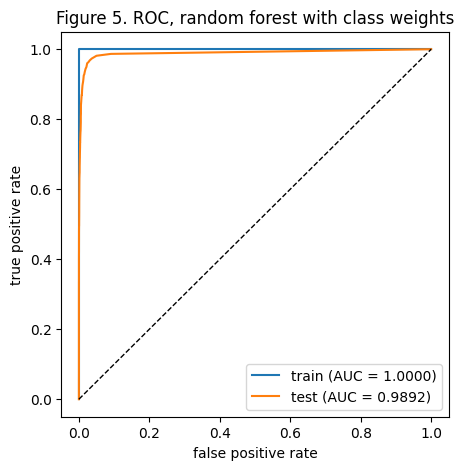

OOB error estimate = 0.0080  |  test error = 0.0109


In [12]:
rf_bal = RandomForestClassifier(n_estimators=100, oob_score=True, class_weight='balanced_subsample',
                                n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
ax = evaluate('RF balanced', rf_bal, X_train, X_test)
ax.set_title('Figure 5. ROC, random forest with class weights'); plt.show()

oob_err_bal = 1 - rf_bal.oob_score_
print(f'OOB error estimate = {oob_err_bal:.4f}  |  test error = {results[-1]["error"]:.4f}')

In [13]:
cmp = pd.DataFrame(results)
cmp = cmp[cmp['split'] == 'test'].set_index('model')[['error', 'auc', 'FP', 'FN']]
cmp['OOB error'] = [oob_err, oob_err_bal]
print(cmp.round(4))

              error     auc  FP   FN  OOB error
model                                          
RF           0.0076  0.9928  15  106     0.0061
RF balanced  0.0109  0.9892  17  158     0.0080


**Comparison with 1(c).** Class weights did not help. Test error rose from 0.0076 to 0.0109, AUC fell from 0.9928 to 0.9892, false negatives rose from 106 to 158 (false positives from 15 to 17), and OOB error rose from 0.0061 to 0.0080. The training metrics are unchanged. The forest without weights is better on every number. Other remedies (under-sampling, threshold moving) were not tested.

## 1(e) XGBoost and model trees

In a model tree the split at each node is decided by a model using all variables. XGBoost is used as suggested, with `objective='binary:logistic'`, and the L1 penalty `reg_alpha` (the regularization term alpha) shrinks the leaf weights so weak leaves are removed.

alpha is chosen by 5-fold stratified cross-validation over a grid, using the misclassification error. The CV error at the chosen alpha is the error estimate, compared with the test error. No imbalance compensation is applied.

In [14]:
ALPHAS = [0.01, 0.1, 1, 10, 100]
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_xgb(alpha):
    return xgb.XGBClassifier(objective='binary:logistic', tree_method='hist', reg_alpha=alpha,
                             n_jobs=-1, random_state=RANDOM_STATE)

cv_err = {a: (cross_val_predict(make_xgb(a), X_train, y_train, cv=cv5) != y_train).mean() for a in ALPHAS}
print(pd.Series(cv_err, name='5-fold CV error').rename_axis('alpha').round(5))
best_alpha = min(cv_err, key=cv_err.get)
print('\nchosen alpha =', best_alpha)

alpha
0.01      0.00635
0.10      0.00660
1.00      0.00638
10.00     0.00893
100.00    0.01157
Name: 5-fold CV error, dtype: float64

chosen alpha = 0.01


XGBoost | train: misclassification = 0.0000, AUC = 1.0000
            pred neg  pred pos
actual neg     59000         0
actual pos         1       999 

XGBoost | test: misclassification = 0.0064, AUC = 0.9937
            pred neg  pred pos
actual neg     15609        16
actual pos        86       289 



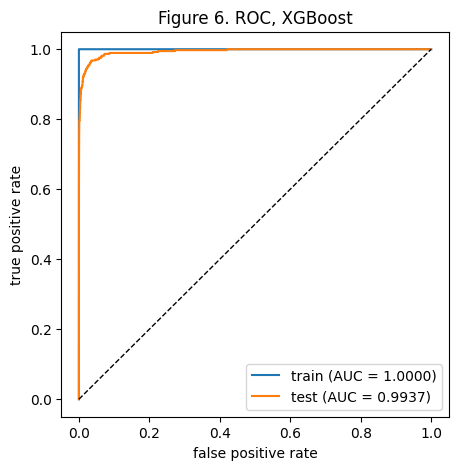

5-fold CV error estimate = 0.0063  |  test error = 0.0064


In [15]:
xgb_model = make_xgb(best_alpha).fit(X_train, y_train)
ax = evaluate('XGBoost', xgb_model, X_train, X_test)
ax.set_title('Figure 6. ROC, XGBoost'); plt.show()
print(f'5-fold CV error estimate = {cv_err[best_alpha]:.4f}  |  test error = {results[-1]["error"]:.4f}')

**Results.** The 5-fold CV errors are 0.00635, 0.00660, 0.00638, 0.00893 and 0.01157 for alpha = 0.01, 0.1, 1, 10 and 100, so alpha = 0.01 is chosen. The first three are practically tied, and a large alpha hurts by shrinking away useful leaves. With alpha = 0.01 the training error is 0.0000 (one false negative, AUC 1.0000). On the test set the error is 0.0064 and the AUC 0.9937, with 16 false positives and 86 false negatives (289 of 375 failures found, 77%).

**CV estimate against test error.** The CV estimate (0.0063) almost equals the test error (0.0064), so cross-validation predicts the test error well. Against the forest of 1(c), XGBoost has a lower test error (0.0064 against 0.0076), 20 fewer false negatives (86 against 106), about the same false positives (16 against 15) and a slightly higher AUC.

## 1(f) XGBoost after SMOTE

SMOTE (Synthetic Minority Over-sampling Technique) creates new positive rows by interpolating between a positive row and one of its nearest positive neighbours, until the classes are the same size. It is applied to the whole imputed training set, because SMOTE cannot handle missing values.

**Cross-validation.** SMOTE is applied inside each fold, to the training part only, and the held-out fold keeps its real balance. Applying SMOTE before splitting would put synthetic copies of a positive row in both parts and make the CV error too optimistic. This is done with an `imblearn` pipeline. The final model is trained on the SMOTE-balanced training set and evaluated on the original training and test sets.

In [16]:
smote = SMOTE(random_state=RANDOM_STATE)
X_smote, y_smote = smote.fit_resample(X_train, y_train)
print('before SMOTE: neg =', int((y_train == 0).sum()), ', pos =', int((y_train == 1).sum()))
print('after SMOTE : neg =', int((y_smote == 0).sum()), ', pos =', int((y_smote == 1).sum()), ', rows =', len(y_smote))

before SMOTE: neg = 59000 , pos = 1000
after SMOTE : neg = 59000 , pos = 59000 , rows = 118000


In [17]:
def make_smote_xgb(alpha):
    return ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)), ('xgb', make_xgb(alpha))])

# SMOTE is refit on the training part of every fold; the validation fold is left untouched
cv_err_sm = {a: (cross_val_predict(make_smote_xgb(a), X_train, y_train, cv=cv5) != y_train).mean() for a in ALPHAS}
print(pd.Series(cv_err_sm, name='5-fold CV error (SMOTE inside folds)').rename_axis('alpha').round(5))
best_alpha_sm = min(cv_err_sm, key=cv_err_sm.get)
print('\nchosen alpha =', best_alpha_sm)

alpha
0.01      0.00650
0.10      0.00657
1.00      0.00633
10.00     0.00783
100.00    0.01758
Name: 5-fold CV error (SMOTE inside folds), dtype: float64

chosen alpha = 1


XGBoost + SMOTE | train: misclassification = 0.0000, AUC = 1.0000
            pred neg  pred pos
actual neg     59000         0
actual pos         1       999 

XGBoost + SMOTE | test: misclassification = 0.0079, AUC = 0.9945
            pred neg  pred pos
actual neg     15554        71
actual pos        56       319 



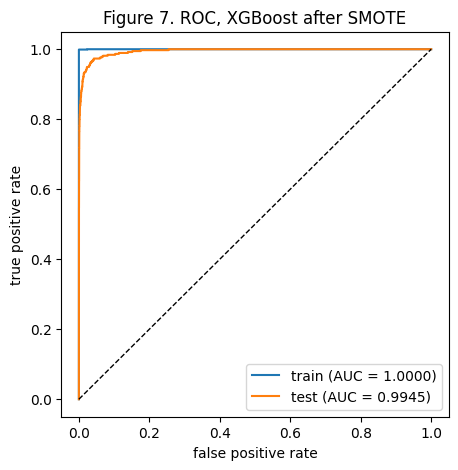

5-fold CV error estimate = 0.0063  |  test error = 0.0079


In [18]:
xgb_smote = make_xgb(best_alpha_sm).fit(X_smote, y_smote)
ax = evaluate('XGBoost + SMOTE', xgb_smote, X_train, X_test)
ax.set_title('Figure 7. ROC, XGBoost after SMOTE'); plt.show()
print(f'5-fold CV error estimate = {cv_err_sm[best_alpha_sm]:.4f}  |  test error = {results[-1]["error"]:.4f}')

In [19]:
summary = pd.DataFrame(results)
summary = summary[summary['split'] == 'test'].set_index('model')[['error', 'auc', 'TN', 'FP', 'FN', 'TP']]
summary['CV or OOB error'] = [oob_err, oob_err_bal, cv_err[best_alpha], cv_err_sm[best_alpha_sm]]
print(summary.round(4))

                  error     auc     TN  FP   FN   TP  CV or OOB error
model                                                                
RF               0.0076  0.9928  15610  15  106  269           0.0061
RF balanced      0.0109  0.9892  15608  17  158  217           0.0080
XGBoost          0.0064  0.9937  15609  16   86  289           0.0064
XGBoost + SMOTE  0.0079  0.9945  15554  71   56  319           0.0063


**Results.** SMOTE grows the training set from 60,000 to 118,000 rows (59,000 of each class). With SMOTE inside the folds, the 5-fold CV errors are 0.00650, 0.00657, 0.00633, 0.00783 and 0.01758 for alpha = 0.01, 0.1, 1, 10 and 100, so alpha = 1 is chosen. The training result is unchanged (error 0.0000, one false negative). On the test set the error is 0.0079 and the AUC 0.9945, with 71 false positives and 56 false negatives (319 of 375 failures found, 85%).

**1(e) against 1(f).** SMOTE moves the classifier toward the positive class: false negatives fall from 86 to 56 (failures found rise from 77% to 85%) while false positives rise from 16 to 71. The error is higher (0.0079 against 0.0064) and the AUC slightly higher (0.9945 against 0.9937). Which is better depends on the relative cost of the two mistakes: if a missed failure costs more than an unnecessary check, the SMOTE model is preferable. The CV estimate (0.0063) is below the test error (0.0079), as the test set has more positives (2.34% against 1.67%).

**All four models** are in the table above: the weighted forest is the weakest, plain XGBoost has the lowest error, and XGBoost with SMOTE has the highest AUC and fewest false negatives.

# 2. ISLR 6.6.3

The coefficients minimize the RSS subject to sum |beta_j| <= s (the lasso, in constraint form).

**(a) Training RSS: iv, steadily decreases.** Increasing s relaxes the constraint, so the allowed set only grows and the smallest achievable RSS can only fall.

**(b) Test RSS: ii, U shape.** At s = 0 the model is the intercept only (high bias). Relaxing the constraint cuts bias and the test RSS drops. For large s the fit approaches least squares, which overfits, so the test RSS rises again.

**(c) Variance: iii, steadily increases.** A larger s gives a more flexible model whose estimates vary more between training sets.

**(d) Squared bias: iv, steadily decreases.** A more flexible model fits the true relationship better.

**(e) Irreducible error: v, constant.** It is the noise variance and does not depend on s.

# 3. ISLR 6.6.5

Setup: n = 2, p = 2, x11 = x12 = a, x21 = x22 = -a, y2 = -y1, intercept 0. Write S = beta1 + beta2. The residuals are y1 - a S and -(y1 - a S), so the RSS is 2 (y1 - a S)^2 and depends on the betas only through S.

**(a) Ridge problem.** Minimize 2 (y1 - a (beta1 + beta2))^2 + lambda (beta1^2 + beta2^2).

**(b) Ridge gives beta1 = beta2.** For a fixed S the first term is fixed, and beta1^2 + beta2^2 = (S^2 + (beta1 - beta2)^2) / 2 is smallest at beta1 = beta2 = S / 2. Solving for S gives beta1 = beta2 = 2 a y1 / (4 a^2 + lambda).

**(c) Lasso problem.** Minimize 2 (y1 - a (beta1 + beta2))^2 + lambda (|beta1| + |beta2|).

**(d) Lasso is not unique.** For a fixed S, |beta1| + |beta2| >= |S|, with equality exactly when beta1 and beta2 do not have opposite signs. So every pair with beta1 + beta2 = S and beta1 * beta2 >= 0 has the same objective. The best S is the soft-thresholded value S* = sign(y1 / a) * max(|y1 / a| - lambda / (4 a^2), 0). When S* is not 0, the solutions are all pairs with beta1 + beta2 = S* and the same sign: the segment from (S*, 0) to (0, S*). Ridge picks its midpoint, while the lasso can return any point of it.

# 4. ISLR 8.4.5

In [20]:
p_red = np.array([0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75])

votes_red = int((p_red > 0.5).sum())
print(f'majority vote: {votes_red} of {len(p_red)} trees say Red, so the class is', 'Red' if votes_red > len(p_red) / 2 else 'Green')
print(f'average probability: {p_red.mean():.2f}, so the class is', 'Red' if p_red.mean() > 0.5 else 'Green')

majority vote: 6 of 10 trees say Red, so the class is Red
average probability: 0.45, so the class is Green


**Majority vote:** six of the ten estimates (0.55, 0.6, 0.6, 0.65, 0.7, 0.75) exceed 0.5, so the final classification is **Red**.

**Average probability:** the mean is 4.5 / 10 = 0.45, below 0.5, so the final classification is **Green**.

The rules disagree: the average is pulled down by the four low estimates (0.1, 0.15, 0.2, 0.2), while the vote counts each tree once.

# 5. ISLR 9.7.3

Seven observations in two dimensions. Red: (3, 4), (2, 2), (4, 4), (1, 4). Blue: (2, 1), (4, 3), (4, 1).

In [21]:
X7 = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
y7 = np.array([1, 1, 1, 1, -1, -1, -1])            # +1 = Red, -1 = Blue

# hard margin: a very large C leaves no room for margin violations
svm = SVC(kernel='linear', C=1e6).fit(X7, y7)
w, b = svm.coef_[0], svm.intercept_[0]
scale = 2 / w[1]                                   # rescale so that beta2 = 1, matching the sketch
print('hyperplane:', f'{b * scale / 2:.2f} + ({w[0] * scale / 2:.2f}) X1 + ({w[1] * scale / 2:.2f}) X2 = 0')
print('support vectors (observations):', sorted(int(i) + 1 for i in svm.support_))
print('margin width (one side):', round(1 / np.linalg.norm(w), 4), '= 1 / (2 sqrt(2)) =', round(1 / (2 * np.sqrt(2)), 4))

hyperplane: 0.50 + (-1.00) X1 + (1.00) X2 = 0
support vectors (observations): [2, 3, 5, 6]
margin width (one side): 0.3537 = 1 / (2 sqrt(2)) = 0.3536


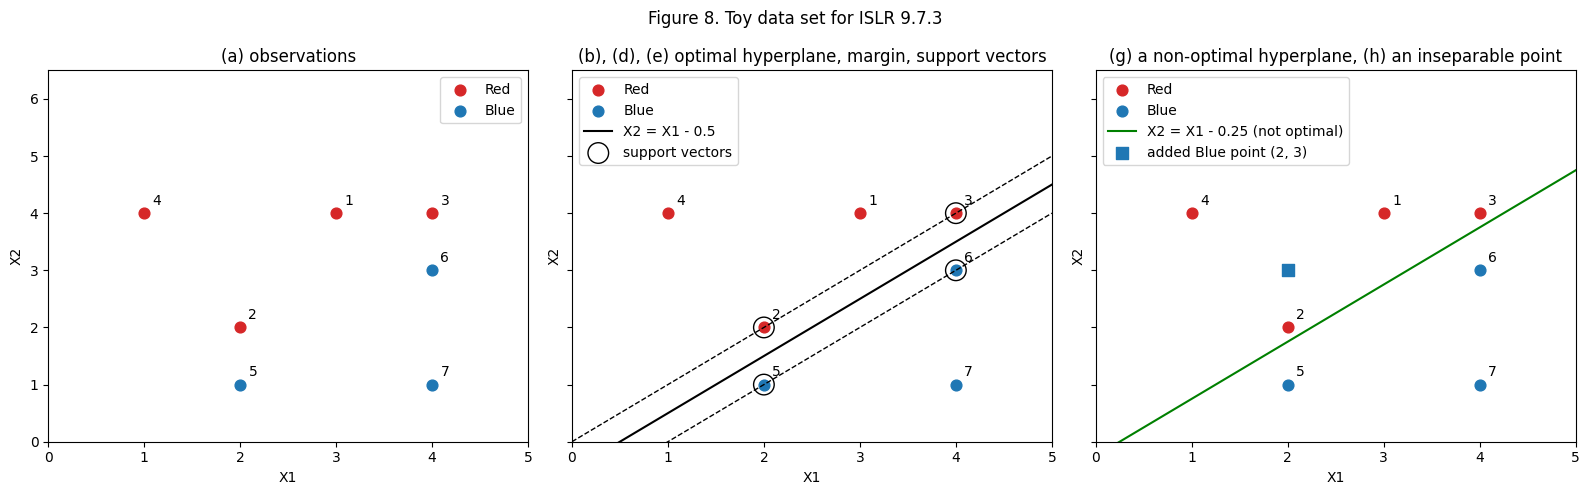

In [22]:
xs = np.linspace(0, 5, 50)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)

def draw(ax, extra=None):
    ax.scatter(*X7[y7 == 1].T, c='tab:red', s=60, label='Red')
    ax.scatter(*X7[y7 == -1].T, c='tab:blue', s=60, label='Blue')
    for i, (x1, x2) in enumerate(X7, start=1):
        ax.annotate(str(i), (x1, x2), textcoords='offset points', xytext=(6, 6))
    ax.set_xlim(0, 5); ax.set_ylim(0, 6.5); ax.set_xlabel('X1'); ax.set_ylabel('X2')

# (a) the observations
draw(axes[0]); axes[0].set_title('(a) observations'); axes[0].legend()

# (b), (d), (e) maximal margin hyperplane, margin, support vectors
draw(axes[1])
axes[1].plot(xs, xs - 0.5, 'k-', label='X2 = X1 - 0.5')
axes[1].plot(xs, xs, 'k--', lw=1); axes[1].plot(xs, xs - 1, 'k--', lw=1)
axes[1].scatter(*X7[[1, 2, 4, 5]].T, s=220, facecolors='none', edgecolors='k', label='support vectors')
axes[1].set_title('(b), (d), (e) optimal hyperplane, margin, support vectors'); axes[1].legend(loc='upper left')

# (g) a separating hyperplane that is not optimal, and (h) a point that breaks separability
draw(axes[2])
axes[2].plot(xs, xs - 0.25, 'g-', label='X2 = X1 - 0.25 (not optimal)')
axes[2].scatter([2], [3], c='tab:blue', marker='s', s=80, label='added Blue point (2, 3)')
axes[2].set_title('(g) a non-optimal hyperplane, (h) an inseparable point'); axes[2].legend(loc='upper left')
fig.suptitle('Figure 8. Toy data set for ISLR 9.7.3')
plt.tight_layout(); plt.show()

In [23]:
def separable(X, y):
    """True if some hyperplane has y (w.x + b) >= 1 for every point (a linear programme feasibility test)."""
    A = -(y[:, None] * np.c_[X, np.ones(len(X))])
    return linprog(np.zeros(3), A_ub=A, b_ub=-np.ones(len(X)), bounds=[(None, None)] * 3).status == 0

print('original 7 points separable:', separable(X7, y7))
print('with an extra Blue point at (2, 3):', separable(np.vstack([X7, [2, 3]]), np.append(y7, -1)))
b_g = 0.25
print('hyperplane 0.25 - X1 + X2 = 0 separates all 7:', bool(np.all(y7 * (b_g - X7[:, 0] + X7[:, 1]) > 0)))

original 7 points separable: True
with an extra Blue point at (2, 3): False
hyperplane 0.25 - X1 + X2 = 0 separates all 7: True


**(a)** See Figure 8, left panel.

**(b) Optimal separating hyperplane.** It lies halfway between the support vectors, on X2 = X1 - 0.5, that is 0.5 - X1 + X2 = 0 (the linear SVM above returns the same coefficients).

**(c) Rule.** Classify to Red if 0.5 - X1 + X2 > 0, and to Blue otherwise: beta0 = 0.5, beta1 = -1, beta2 = 1.

**(d) Margin.** It is bounded by the lines X2 = X1 and X2 = X1 - 1. The half width is 1 / (2 sqrt(2)) = 0.354 (total width 0.707).

**(e) Support vectors.** Observations 2 (2, 2), 3 (4, 4), 5 (2, 1) and 6 (4, 3).

**(f) Observation 7.** (4, 1) is at distance |0.5 - 4 + 1| / sqrt(2) = 1.77 from the hyperplane, far outside the margin. The hyperplane depends only on the support vectors, so a slight movement of observation 7 does not change it.

**(g) A non-optimal hyperplane.** 0.25 - X1 + X2 = 0 still separates the classes (checked above), but its margin is 0.25 / sqrt(2) = 0.177, smaller than 0.354.

**(h) Inseparable data.** Adding a Blue observation at (2, 3), inside the region spanned by the Red points, makes the classes impossible to separate by a hyperplane (the check above finds none).

## References

1. UCI Machine Learning Repository, APS Failure at Scania Trucks Data Set: https://archive.ics.uci.edu/ml/datasets/APS+Failure+at+Scania+Trucks
2. scikit-learn, imputation of missing values: https://scikit-learn.org/stable/modules/impute.html
3. scikit-learn, RandomForestClassifier (`class_weight`, `oob_score`): https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
4. imbalanced-learn, SMOTE: https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html
5. imbalanced-learn, common pitfalls (resampling inside cross-validation): https://imbalanced-learn.org/stable/common_pitfalls.html
6. N. V. Chawla, K. W. Bowyer, L. O. Hall, W. P. Kegelmeyer, SMOTE: Synthetic Minority Over-sampling Technique, Journal of Artificial Intelligence Research 16 (2002) 321-357: https://doi.org/10.1613/jair.953
7. XGBoost documentation, parameters (`reg_alpha`, `objective`): https://xgboost.readthedocs.io/en/stable/parameter.html
8. G. James, D. Witten, T. Hastie, R. Tibshirani, An Introduction to Statistical Learning, exercises 6.6.3, 6.6.5, 8.4.5 and 9.7.3, and Figure 4.1 (p. 129).